# 6DRepNet360: feature extractor evaluation

Run with the **6DRepNet360** kernel (env in `envs/6DRepNet360/`).

There is no ground truth yet, so section 5 checks coverage, plausibility, and stability instead of accuracy. The current test set is `data/test_pictures/` (still images, i.e. one-frame clips, in three categories: gaze, emotion, head_pose). 6DRepNet360 only estimates head pose, so this notebook runs the **head_pose** category: 34 images, 2 camera positions × (3 head pitches × 5 head yaws + 2 head tilts). The manifest's `approx_head_yaw_deg` (0, ±45, ±90) gives a rough expected yaw. Section 5 ends with a side-by-side comparison against 6DRepNet (notebook 05) on the same pictures.

## Notes and verdict

**Hardware used for the speed numbers:** RTX 2080 SUPER 8 GB, CUDA 12.6

**Known from setup (before running on test data):**
- Head pose only: no gaze, no AUs.
- Successor of 6DRepNet (same authors, IEEE TIP 2024): ResNet-50 backbone predicting a 6D rotation, trained for the full range of yaw (360°). The Full Rotation weights are trained on 300W-LP + CMU Panoptic.
- No inference package, demo, or sample images in the repo (README usage: "Coming soon"); only `test.py` (evaluation on datasets). The notebook rebuilds inference from `test.py`.
- No face detector in the repo; YuNet (OpenCV) is used, with the training crop margin.
- Sign conventions are not documented.
- Code license MIT; weights license not stated.

**Tested on:** `test_pictures`, head_pose category only (34 still images of one researcher: 3 head pitches × 5 head yaws + 2 tilts, front and below camera), Full Rotation weights. No videos and no ground truth; the manifest's yaw labels (0, ±45, ±90°) are rough, so everything below is by eye.

**Strengths:**
- Same sign conventions as 6DRepNet, and directions are right on most detected pictures (yaw, pitch, and roll).
- Level head, front camera: three-quarter views read ±43° (≈45°), profiles +75° / −70°, full face ≈0°.
- Tilt is clear and symmetric: +32° / −26° (front) and +33° / −29° (below).
- Less pitch offset from the below camera than 6DRepNet: a level head from below reads about 0 to +7° (6DRepNet: about +22°).
- Fast: about 22–23 images/s for YuNet + 6DRepNet360 on 1280×720 images.

**Weaknesses:**
- **Wrong answers on pictures with a good face box**, where 6DRepNet was right: `front_upturned-profile-right` yaw +20° (should be about −90°, wrong sign), `below_profile-right` yaw −3° (should be about −90°), `below_three-quarter-right` yaw −19° (6DRepNet −32°), `front_profile-left` pitch +53° and roll −60° with a level head.
- Up and down are weaker than 6DRepNet on the front camera: upturned +13 to +29° (6DRepNet +31 to +46°), downturned −21 to −27° (6DRepNet −29 to −32°).
- **Upturned heads from the below camera:** the same YuNet failures as 6DRepNet (3 of 5 missed). On the two bad boxes (`below_upturned-full-face`, `below_upturned-profile-left`) the full-range model answers with pitch ≈ ±170° and roll ≈ ±135 to 176°, i.e. it thinks it sees the back of the head. This is face detection, not the pose model, but the outputs fall outside any range we'd expect from a seated subject, so they would need filtering.
- No inference code: the crop margin is my choice from the training code (the repo has no demo), so results depend on it. `Resize(256)` + `CenterCrop(224)` on a tall crop cuts off the chin and the top of the head (see "Crops fed to the model").
- The full 360° range isn't needed here: the subject always faces the screen.
- Head pose only: no gaze, no AUs. No face detector in the repo (YuNet added); weights license not stated.

**Verdict:** drop (6DRepNet is better on these pictures)

**Why:** On the same pictures and detector it makes four clear mistakes on good face boxes that 6DRepNet gets right, and its up/down range is smaller. Its main extra feature, full-range yaw, doesn't matter for a seated subject facing the screen. One point in its favour: less pitch offset from the below camera. Since the repo has no inference code, a different crop could change the results; revisit only if 6DRepNet has trouble on videos.

## Setup

Imports and paths. Run this first.

In [1]:
import importlib.util
import sys
import time
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torchvision
from PIL import Image
from torchvision import transforms

from src import clip_io, plots, schema

ROOT = clip_io.REPO_ROOT
MODEL = '6DRepNet360'
MODEL_DIR = ROOT / 'models' / MODEL
WEIGHTS = MODEL_DIR / 'weights' / '6DRepNet360_Full-Rotation_300W_LP+Panoptic.pth'
# Alternative weights (300W-LP only): MODEL_DIR / 'weights' / '6DRepNet360_300W_LP.pth'
YUNET_PATH = ROOT / 'models' / 'YuNet' / 'face_detection_yunet_2026may.onnx'
DEVICE = 'cuda:0'

## 1. Model card

| Field | Value |
|---|---|
| Paper | Hempel, Abdelrahman, Al-Hamadi. *Toward Robust and Unconstrained Full Range of Rotation Head Pose Estimation.* IEEE Transactions on Image Processing 33, 2024 (extends *6D Rotation Representation for Unconstrained Head Pose Estimation*, ICIP 2022) |
| Repo URL | https://github.com/thohemp/6DRepNet360 |
| Commit hash | `b06e4fed77f802fbf05319b85bb65215087d5c7a` (2024-06-10) |
| Code license | MIT (`LICENSE.MD`) |
| Inference code | No package, demo, or sample images; README usage says "Coming soon". The model class `SixDRepNet360` and its preprocessing come from `sixdrepnet360/test.py`, loaded by file path under the name `sixdrepnet360_test` (the name `test` clashes with Python's standard-library `test` package). `test.py` imports the repo's `utils` and `datasets` as top-level modules, so `sixdrepnet360/` is put on `sys.path`. Repo code unchanged |
| Weights | `models/6DRepNet360/weights/6DRepNet360_Full-Rotation_300W_LP+Panoptic.pth` (94,397,849 bytes, SHA-256 `3ee08f1e04b8d452a6c4a40926a6f38051894ae6d0aaa6d191fe6d8bc6e4f9c6`), from https://cloud.ovgu.de/s/TewGC9TDLGgKkmS/download/6DRepNet360_Full-Rotation_300W_LP+Panoptic.pth (the default in `test.py`). Trained on 300W-LP + CMU Panoptic. Also downloaded, not used here: `6DRepNet360_300W_LP.pth` (94,395,273 bytes, SHA-256 `f4af3f74ed7dc4919c8db0af8911731c93b7780df44a268a561b45ab8265a536`), from https://cloud.ovgu.de/s/wWCitDxp9t79xkP/download/6DRepNet360_300W_LP.pth. Both files are plain state dicts (320 tensors) |
| Weights license | **Not stated** (README and `LICENSE.MD` cover the code only) |
| Face detector | Not in the repo. Here: OpenCV YuNet, `models/YuNet/face_detection_yunet_2026may.onnx` (MIT), same as GazeTR and 6DRepNet |
| Pipeline | YuNet face box → loose crop with the training margins (see section 3) → RGB → `Resize(256)`, `CenterCrop(224)`, ImageNet normalization (as in `test.py`) → ResNet-50 → 6D rotation → rotation matrix → `utils.compute_euler_angles_from_rotation_matrices` → pitch, yaw, roll |
| Inputs required | Face crop, RGB |
| Outputs | Head pose: rotation matrix, converted to pitch, yaw, roll in degrees. **No gaze, no AUs** |
| Native units / conventions | Radians from the Euler conversion, converted to degrees (×180/π) as in `test.py`. Signs undocumented; on `test_pictures` (same as 6DRepNet): yaw negative when the subject turns to their left, pitch positive when the head is turned up, roll positive when tilted toward the subject's left shoulder. Full-range model: pitch and roll can approach ±180° when it believes it sees the back of the head |
| Conversion to schema | `pose_yaw_deg` = **−**yaw, `pose_pitch_deg` = pitch, `pose_roll_deg` = roll (same as 6DRepNet; checked on `test_pictures`). Raw outputs kept as `extra_pose_raw_pitch/yaw/roll`. YuNet score → `face_conf`; detection box → `extra_bbox_*` |
| Env | `envs/6DRepNet360/` (pyproject.toml + uv.lock), kernel `6DRepNet360`: Python 3.11.17, torch 2.14.1+cu126 |

In [2]:
!git -C {MODEL_DIR} remote get-url origin
!git -C {MODEL_DIR} rev-parse HEAD

git@github.com:thohemp/6DRepNet360.git
b06e4fed77f802fbf05319b85bb65215087d5c7a


## 2. Setup log

Ubuntu, uv 0.13.0, Python 3.11.17, torch 2.14.1+cu126 (CUDA runtime 12.6), driver 580.178.04, RTX 2080 SUPER (sm_75).

| # | Step / command | Result | Error | Fix |
|---|---|---|---|---|
| 1 | Inspect repo | Not installable (no `setup.py`/`pyproject.toml`), no requirements file, no demo; model and preprocessing in `sixdrepnet360/test.py`; weights downloaded separately | No dependency list | Dependencies taken from the repo's imports (torch, torchvision, numpy, opencv, scipy, pandas, Pillow, matplotlib) |
| 2 | `uv init --bare --no-workspace --python 3.11`; `uv python pin 3.11` | `envs/6DRepNet360/` created | | |
| 3 | cu126 index (`explicit = true`) + `uv add torch torchvision` | torch 2.14.1+cu126, torchvision 0.29.1+cu126; CUDA available, sm_75 supported | | |
| 4 | `uv add numpy opencv-python scipy pandas pillow matplotlib`; `uv add --editable ../..` | numpy 2.4.6, opencv-python 5.0.0.93, pandas 3.0.6, Pillow 12.3.0, scipy 1.17.1, matplotlib 3.11.2, pyarrow 26.0.0 (same versions as the 6DRepNet env) | | |
| 5 | `uv add --dev ipykernel`; `ipykernel install --user --name 6DRepNet360` | Kernel `6DRepNet360` | | |
| 6 | Import `sixdrepnet360/test.py` | Imports work when loaded by file path | `import test` would pick up Python's standard-library `test` package | Load `test.py` by file path with `importlib` under the name `sixdrepnet360_test`; no repo edit |
| 7 | Weights downloaded manually to `models/6DRepNet360/weights/`; `torch.load(..., weights_only=True)` → `load_state_dict(strict=True)` | Both files: 320 tensors, all keys matched; plain state dicts (no `model_state_dict` wrapper) | | |
| 8 | Forward pass on a dummy 224×224 input on GPU (repo has no sample images) | (1, 3, 3) rotation matrix, det = 1; Euler conversion gives 3 angles | | |

## 3. Run on test clips

- **Detection:** YuNet on the full frame; only the top-scoring face is used, and only if its score is ≥ 0.5.
- **Crop:** the repo has no inference crop, so this follows the training crop (`datasets.Pose_300W_LP`): around the landmark box, x by 0.6·k of the width on each side, the top by 2·k of the height and the bottom by about 0.6·k, with k random in 0.2–0.4. The YuNet box is a little looser than a landmark box, so the smallest k = 0.2 is used: **12% each side, 40% top, 12% bottom**, clipped to the image. `Resize(256)` + `CenterCrop(224)` then follow, as in `test.py`.

In [3]:
# test.py imports the repo's utils and datasets as top-level modules
REPO_CODE = MODEL_DIR / 'sixdrepnet360'
sys.path.insert(0, str(REPO_CODE))
sys.dont_write_bytecode = True  # keep __pycache__ out of the cloned repo
# Load test.py by path: the name 'test' clashes with Python's standard-library test package
spec = importlib.util.spec_from_file_location('sixdrepnet360_test', REPO_CODE / 'test.py')
repo_test = importlib.util.module_from_spec(spec)
spec.loader.exec_module(repo_test)
import utils as repo_utils  # sixdrepnet360/utils.py

# Model as built in test.py
model = repo_test.SixDRepNet360(torchvision.models.resnet.Bottleneck, [3, 4, 6, 3], 6)
state = torch.load(WEIGHTS, map_location='cpu', weights_only=True)
model.load_state_dict(state.get('model_state_dict', state))  # test.py accepts either layout
model.to(DEVICE).eval()

# Preprocessing from test.py
transform = transforms.Compose([
    transforms.Resize(256), transforms.CenterCrop(224), transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

DET_THRESHOLD = 0.5
# Input size is a placeholder; detect() sets it to each frame's size
detector = cv2.FaceDetectorYN.create(str(YUNET_PATH), '', (320, 320), DET_THRESHOLD)

[ WARN:0@4.056] global net_impl_backend.cpp:345 setPreferableTarget Targets are not supported by the new graph engine for now


In [4]:
MARGIN_SIDE, MARGIN_TOP, MARGIN_BOTTOM = 0.12, 0.40, 0.12  # training crop with k = 0.2, see above

OUTPUT_COLUMNS = (
    ['pose_yaw_deg', 'pose_pitch_deg', 'pose_roll_deg']
    + ['extra_pose_raw_pitch', 'extra_pose_raw_yaw', 'extra_pose_raw_roll']
    + ['extra_bbox_x1', 'extra_bbox_y1', 'extra_bbox_x2', 'extra_bbox_y2']
)


def detect(image):
    """Top YuNet face as (score, (x, y, w, h)), or (0.0, None) if there is none."""
    h, w = image.shape[:2]
    detector.setInputSize((w, h))
    _, faces = detector.detect(image)
    if faces is None or len(faces) == 0:
        return 0.0, None
    top = faces[np.argmax(faces[:, -1])]
    return float(top[-1]), top[:4]


def crop_face(image, box):
    """Box widened by the training margins, clipped to the image."""
    x, y, bw, bh = box
    h, w = image.shape[:2]
    x1, y1 = max(0, int(x - MARGIN_SIDE * bw)), max(0, int(y - MARGIN_TOP * bh))
    x2, y2 = min(w, int(x + bw + MARGIN_SIDE * bw)), min(h, int(y + bh + MARGIN_BOTTOM * bh))
    return image[y1:y2, x1:x2]


def predict(image):
    """Run YuNet + 6DRepNet360 on one BGR frame. Returns (face_conf, outputs or None)."""
    face_conf, box = detect(image)
    if box is None or face_conf < DET_THRESHOLD:
        return face_conf, None

    face = Image.fromarray(cv2.cvtColor(crop_face(image, box), cv2.COLOR_BGR2RGB))
    with torch.no_grad():
        R = model(transform(face).unsqueeze(0).to(DEVICE))
        euler = repo_utils.compute_euler_angles_from_rotation_matrices(R) * 180 / np.pi
    pitch, yaw, roll = (float(v) for v in euler[0].cpu())  # degrees, order as in test.py

    x, y, bw, bh = box
    return face_conf, {
        # Native yaw is negative when the subject turns to their left, so flip it (same as 6DRepNet).
        # Pitch (up = positive) and roll (toward the left shoulder = positive) already match the schema. See model card.
        'pose_yaw_deg': -yaw,
        'pose_pitch_deg': pitch,
        'pose_roll_deg': roll,
        'extra_pose_raw_pitch': pitch, 'extra_pose_raw_yaw': yaw, 'extra_pose_raw_roll': roll,
        'extra_bbox_x1': float(x), 'extra_bbox_y1': float(y),
        'extra_bbox_x2': float(x + bw), 'extra_bbox_y2': float(y + bh),
    }

In [5]:
CATEGORIES = ['head_pose']
TEST_SET = 'test_pictures'  # folder under data/ with manifest.csv
manifest = clip_io.load_manifest(TEST_SET, CATEGORIES)
manifest

,clip_id,path,test_set,category,camera,gaze_target,expected_emotion,head_yaw,head_pitch,head_roll,approx_head_yaw_deg
0,front_full-face,head_pose/front_full-face.jpeg,test_pictures,head_pose,front,NaN,NaN,full-face,level,none,0.0
1,front_three-quarter-left,head_pose/front_three-quarter-left.jpeg,test_pictures,head_pose,front,NaN,NaN,three-quarter-left,level,none,45.0
2,front_three-quarter-right,head_pose/front_three-quarter-right.jpeg,test_pictures,head_pose,front,NaN,NaN,three-quarter-right,level,none,-45.0
3,front_profile-left,head_pose/front_profile-left.jpeg,test_pictures,head_pose,front,NaN,NaN,profile-left,level,none,90.0
4,front_profile-right,head_pose/front_profile-right.jpeg,test_pictures,head_pose,front,NaN,NaN,profile-right,level,none,-90.0
5,front_upturned-full-face,head_pose/front_upturned-full-face.jpeg,test_pictures,head_pose,front,NaN,NaN,full-face,upturned,none,0.0
6,front_upturned-three-quarter-left,head_pose/front_upturned-three-quarter-left.jpeg,test_pictures,head_pose,front,NaN,NaN,three-quarter-left,upturned,none,45.0
7,front_upturned-three-quarter-right,head_pose/front_upturned-three-quarter-right.jpeg,test_pictures,head_pose,front,NaN,NaN,three-quarter-right,upturned,none,-45.0
8,front_upturned-profile-left,head_pose/front_upturned-profile-left.jpeg,test_pictures,head_pose,front,NaN,NaN,profile-left,upturned,none,90.0
9,front_upturned-profile-right,head_pose/front_upturned-profile-right.jpeg,test_pictures,head_pose,front,NaN,NaN,profile-right,upturned,none,-90.0


In [6]:
results, timings = {}, {}
for row in manifest.itertuples():
    records = []
    t0 = time.perf_counter()
    for frame, timestamp_ms, image in clip_io.iter_frames(clip_io.clip_path(row)):
        face_conf, outputs = predict(image)
        record = {'clip_id': row.clip_id, 'frame': frame, 'timestamp_ms': timestamp_ms,
                  'face_conf': float(face_conf) if outputs is not None else 0.0}
        record.update(outputs or {})
        records.append(record)
    timings[row.clip_id] = time.perf_counter() - t0
    results[row.clip_id] = pd.DataFrame.from_records(records, columns=list(schema.REQUIRED_COLUMNS) + OUTPUT_COLUMNS)
    print(f'{row.clip_id}: {len(records)} frames in {timings[row.clip_id]:.1f} s')

front_full-face: 1 frames in 0.3 s
front_three-quarter-left: 1 frames in 0.1 s
front_three-quarter-right: 1 frames in 0.0 s
front_profile-left: 1 frames in 0.0 s
front_profile-right: 1 frames in 0.0 s
front_upturned-full-face: 1 frames in 0.0 s
front_upturned-three-quarter-left: 1 frames in 0.0 s
front_upturned-three-quarter-right: 1 frames in 0.0 s
front_upturned-profile-left: 1 frames in 0.0 s
front_upturned-profile-right: 1 frames in 0.0 s
front_downturned-full-face: 1 frames in 0.0 s
front_downturned-three-quarter-left: 1 frames in 0.0 s
front_downturned-three-quarter-right: 1 frames in 0.0 s
front_downturned-profile-left: 1 frames in 0.0 s
front_downturned-profile-right: 1 frames in 0.0 s
front_tilt-left: 1 frames in 0.0 s
front_tilt-right: 1 frames in 0.0 s
below_full-face: 1 frames in 0.0 s
below_three-quarter-left: 1 frames in 0.0 s
below_three-quarter-right: 1 frames in 0.0 s
below_profile-left: 1 frames in 0.0 s
below_profile-right: 1 frames in 0.0 s
below_upturned-full-face:

## 4. Save output in the common schema

`save_output` runs `schema.validate` and refuses to write a file that fails it. Fix the conversion in `predict`, not the check.

In [7]:
for clip_id, df in results.items():
    df = df.astype({'frame': 'int64', 'timestamp_ms': 'float64', 'face_conf': 'float64'})
    out_cols = [c for c in df.columns if c not in schema.REQUIRED_COLUMNS and not c.startswith(schema.EXTRA_PREFIX)]
    df[out_cols] = df[out_cols].astype('float64')
    df = schema.add_missing_au_pairs(df)
    print(clip_io.save_output(df, MODEL, clip_id))

/home/ciber/Desktop/extractor-eval/outputs/6DRepNet360/front_full-face.parquet
/home/ciber/Desktop/extractor-eval/outputs/6DRepNet360/front_three-quarter-left.parquet
/home/ciber/Desktop/extractor-eval/outputs/6DRepNet360/front_three-quarter-right.parquet
/home/ciber/Desktop/extractor-eval/outputs/6DRepNet360/front_profile-left.parquet
/home/ciber/Desktop/extractor-eval/outputs/6DRepNet360/front_profile-right.parquet
/home/ciber/Desktop/extractor-eval/outputs/6DRepNet360/front_upturned-full-face.parquet
/home/ciber/Desktop/extractor-eval/outputs/6DRepNet360/front_upturned-three-quarter-left.parquet
/home/ciber/Desktop/extractor-eval/outputs/6DRepNet360/front_upturned-three-quarter-right.parquet
/home/ciber/Desktop/extractor-eval/outputs/6DRepNet360/front_upturned-profile-left.parquet
/home/ciber/Desktop/extractor-eval/outputs/6DRepNet360/front_upturned-profile-right.parquet
/home/ciber/Desktop/extractor-eval/outputs/6DRepNet360/front_downturned-full-face.parquet
/home/ciber/Desktop/ext

## 5. Quick checks

These read back the saved files, so they test exactly what was written.

In [8]:
out = clip_io.load_outputs(MODEL, manifest['clip_id'])  # only this run's clips, not leftovers from other runs
print('output columns:', schema.output_columns(out))

output columns: ['pose_yaw_deg', 'pose_pitch_deg', 'pose_roll_deg']


### Face-detection rate

,detection_rate
clip_id,
below_downturned-full-face,1.0
below_downturned-profile-left,1.0
below_downturned-profile-right,1.0
below_downturned-three-quarter-left,1.0
below_downturned-three-quarter-right,1.0
below_full-face,1.0
below_profile-left,1.0
below_profile-right,1.0
below_three-quarter-left,1.0


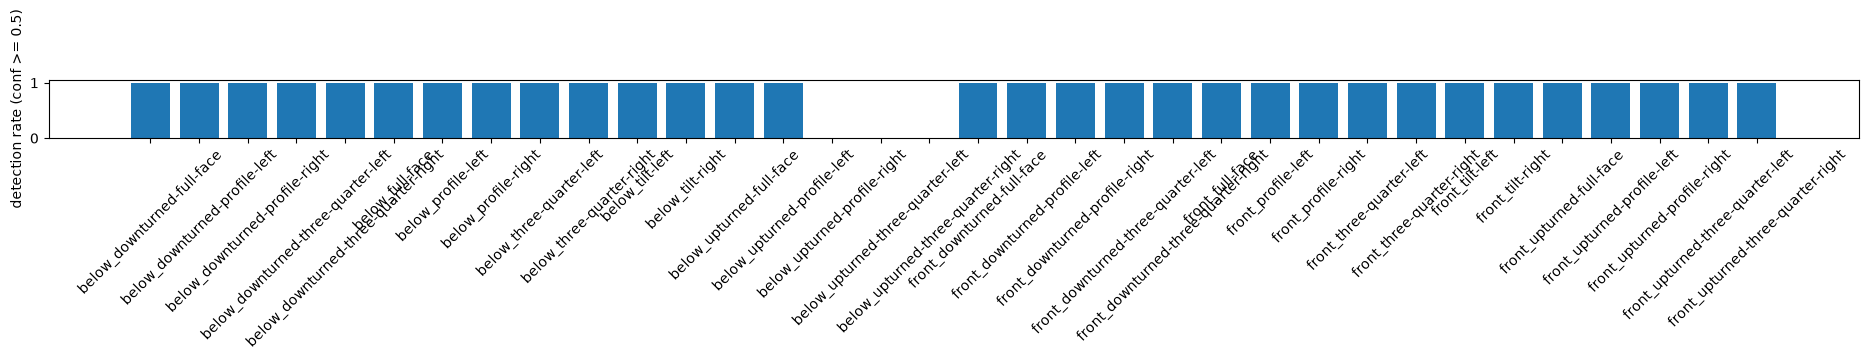

In [9]:
display(plots.detection_rate(out, threshold=DET_THRESHOLD).to_frame())
plots.plot_detection_rate(out, threshold=DET_THRESHOLD);

### Speed (fps on this machine)

Includes video decoding and face detection. Note the hardware (CPU/GPU) in the verdict.

In [10]:
plots.fps_table(timings, out)

,n_frames,seconds,fps
below_downturned-full-face,1,0.042182,23.706748
below_downturned-profile-left,1,0.041451,24.124642
below_downturned-profile-right,1,0.042189,23.703018
below_downturned-three-quarter-left,1,0.044665,22.388827
below_downturned-three-quarter-right,1,0.042141,23.729695
below_full-face,1,0.044866,22.288837
below_profile-left,1,0.041838,23.901518
below_profile-right,1,0.041710,23.975010
below_three-quarter-left,1,0.043687,22.890262
below_three-quarter-right,1,0.042939,23.288994


### Per-clip summary

One row per clip with mean outputs over detected frames, next to the manifest's head-pose labels. `yaw_error_deg` compares `pose_yaw_deg` with the manifest's rough `approx_head_yaw_deg` (0, ±45, ±90), so treat it as a sanity check, not accuracy.

In [11]:
detected = out[out['face_conf'] >= DET_THRESHOLD]
summary = detected.groupby('clip_id').agg(
    n_frames=('frame', 'size'), face_conf=('face_conf', 'mean'),
    pose_yaw_deg=('pose_yaw_deg', 'mean'), pose_pitch_deg=('pose_pitch_deg', 'mean'), pose_roll_deg=('pose_roll_deg', 'mean'),
)
labels = manifest.set_index('clip_id').drop(columns=['path', 'test_set']).dropna(axis=1, how='all')  # skip label columns unused by these categories
summary = labels.join(summary, how='left')
summary['yaw_error_deg'] = summary['pose_yaw_deg'] - summary['approx_head_yaw_deg']
summary.round(1)

,category,camera,head_yaw,head_pitch,head_roll,approx_head_yaw_deg,n_frames,face_conf,pose_yaw_deg,pose_pitch_deg,pose_roll_deg,yaw_error_deg
clip_id,,,,,,,,,,,,
front_full-face,head_pose,front,full-face,level,none,0.0,1.0,0.9,1.6,-14.3,-0.4,1.6
front_three-quarter-left,head_pose,front,three-quarter-left,level,none,45.0,1.0,0.9,42.7,-7.9,0.0,-2.3
front_three-quarter-right,head_pose,front,three-quarter-right,level,none,-45.0,1.0,0.9,-43.0,-10.5,-4.9,2.0
front_profile-left,head_pose,front,profile-left,level,none,90.0,1.0,0.9,75.1,52.8,-59.5,-14.9
front_profile-right,head_pose,front,profile-right,level,none,-90.0,1.0,0.9,-69.8,-2.6,0.5,20.2
front_upturned-full-face,head_pose,front,full-face,upturned,none,0.0,1.0,0.9,2.3,16.4,12.7,2.3
front_upturned-three-quarter-left,head_pose,front,three-quarter-left,upturned,none,45.0,1.0,0.9,21.8,13.1,4.1,-23.2
front_upturned-three-quarter-right,head_pose,front,three-quarter-right,upturned,none,-45.0,1.0,0.9,-34.6,29.3,14.0,10.4
front_upturned-profile-left,head_pose,front,profile-left,upturned,none,90.0,1.0,0.9,50.5,81.9,-68.4,-39.5


In [12]:
# Mean pose per label, separately for each camera (NaN = no detection)
for col in ['head_yaw', 'head_pitch', 'head_roll']:
    display(summary.pivot_table(index=col, columns='camera', values=['pose_yaw_deg', 'pose_pitch_deg', 'pose_roll_deg'], aggfunc='mean').round(1))

pose_pitch_deg       pose_roll_deg       pose_yaw_deg  \
camera                       below front         below front        below   
head_yaw                                                                    
full-face                     40.4  -6.9         -33.0   3.4          3.3   
profile-left                  59.2  28.9         -43.2 -29.3         48.5   
profile-right                  9.8 -11.0           6.4   9.8        -29.3   
three-quarter-left            -6.6  -7.2           8.6   4.5         40.6   
three-quarter-right           -6.1  -0.7          -8.4   0.2        -25.1   

                           
camera              front  
head_yaw                   
full-face             2.0  
profile-left         64.7  
profile-right       -36.4  
three-quarter-left   33.4  
three-quarter-right -33.6

pose_pitch_deg       pose_roll_deg       pose_yaw_deg      
camera              below front         below front        below front
head_pitch                                                            
downturned          -14.4 -28.2           4.6   3.7          2.5   4.4
level                15.3   0.4           0.9  -8.2         14.8   1.9
upturned            169.3  26.7        -155.4   2.3          9.2  11.9

pose_pitch_deg       pose_roll_deg       pose_yaw_deg      
camera              below front         below front        below front
head_roll                                                             
none                 27.7   0.7         -23.8  -2.3         10.8   5.9
tilt-left            16.4  -8.4          33.0  32.4          2.2  -4.5
tilt-right           24.7  -6.4         -28.6 -25.5          3.2  10.9

### Detections on single-image clips

Top face box and confidence on each image, one grid per manifest category, with the predicted head pose drawn from the schema columns (so it also checks the sign conversion): the blue arrow is where the face points (yaw, pitch), the orange line is the tilt (roll).

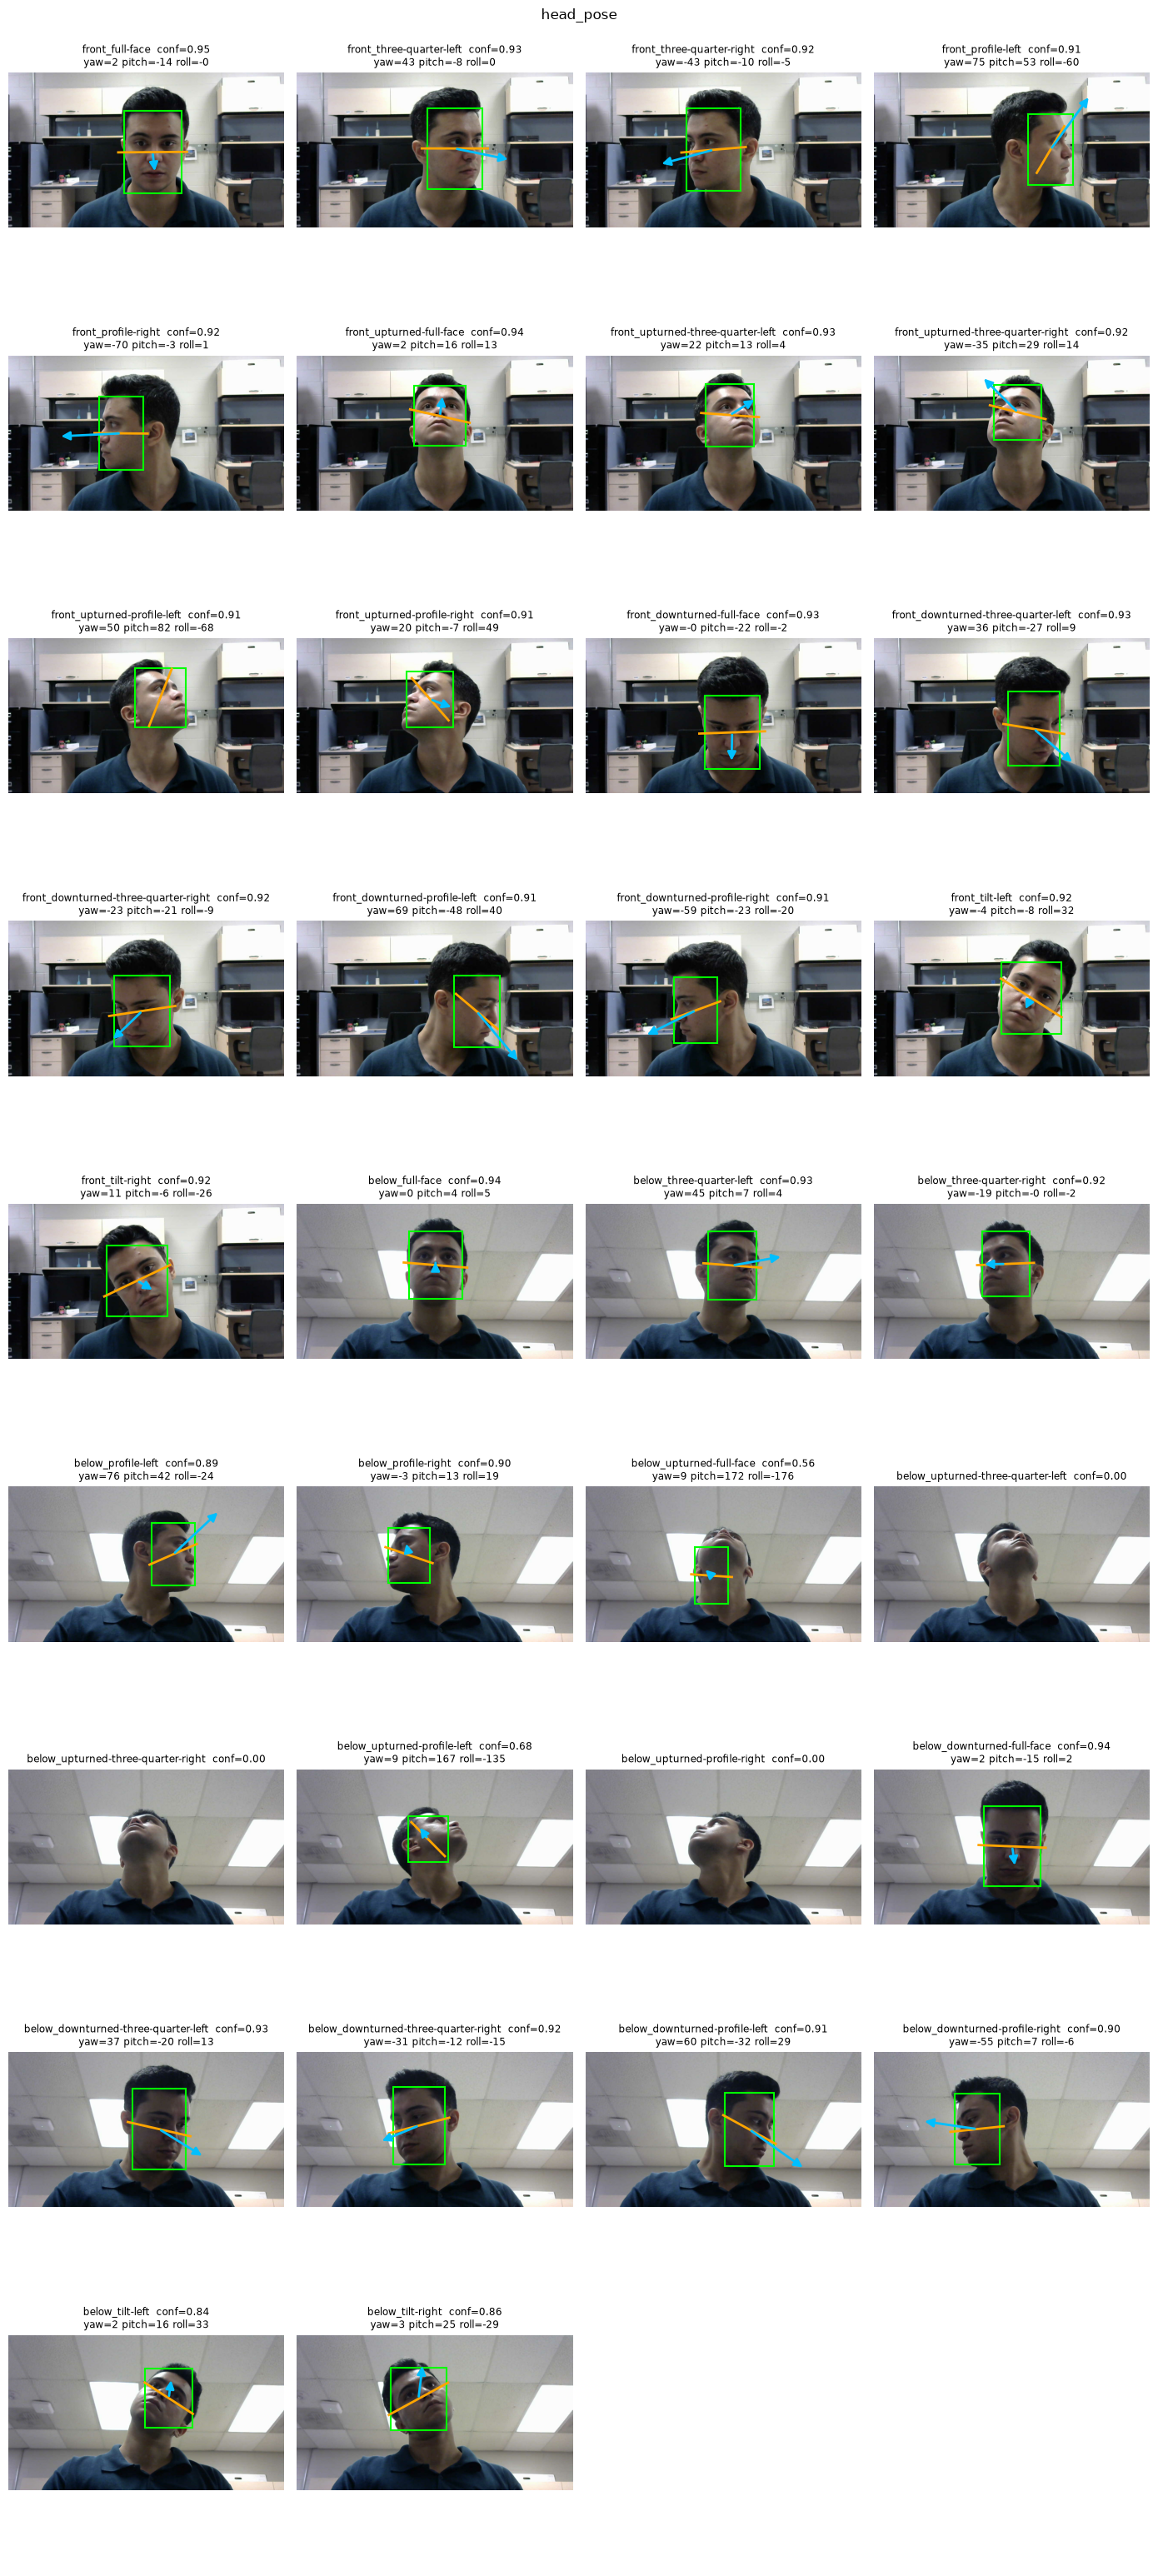

In [13]:
def draw_pose(ax, r):
    """Face-direction arrow (yaw, pitch) and a roll line, from the schema columns.
    Assumes a true-orientation image: the subject's left is the image's right."""
    if pd.isna(r['pose_yaw_deg']):
        return
    x1, y1, x2, y2 = r[['extra_bbox_x1', 'extra_bbox_y1', 'extra_bbox_x2', 'extra_bbox_y2']]
    cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
    size = x2 - x1
    yaw, pitch, roll = np.radians(r[['pose_yaw_deg', 'pose_pitch_deg', 'pose_roll_deg']].astype(float))
    dx = 1.5 * size * np.sin(yaw) * np.cos(pitch)  # positive yaw (subject's left) -> image right
    dy = -1.5 * size * np.sin(pitch)               # positive pitch (up) -> image up
    ax.annotate('', xy=(cx + dx, cy + dy), xytext=(cx, cy),
                arrowprops=dict(arrowstyle='-|>', color='deepskyblue', lw=2, mutation_scale=15))
    # Roll: positive (toward the subject's left shoulder = image right) turns the line clockwise on screen
    lx, ly = 0.6 * size * np.cos(roll), 0.6 * size * np.sin(roll)
    ax.plot([cx - lx, cx + lx], [cy - ly, cy + ly], color='orange', lw=2)


groups = manifest.groupby('category', sort=False) if 'category' in manifest else [('all clips', manifest)]
for category, rows in groups:
    still = [r for r in rows.itertuples() if clip_io.is_image(clip_io.clip_path(r))]
    if not still:
        continue
    ncols = 4
    fig, axes = plt.subplots(-(-len(still) // ncols), ncols, figsize=(3.5 * ncols, 3.5 * -(-len(still) // ncols)), squeeze=False)
    for ax in axes.flat:
        ax.axis('off')
    for ax, row in zip(axes.flat, still):
        _, _, img = next(clip_io.iter_frames(clip_io.clip_path(row), rgb=True))
        r = out[out['clip_id'] == row.clip_id].iloc[0]
        ax.imshow(img)
        title = f"{row.clip_id}  conf={r['face_conf']:.2f}"
        if r['face_conf'] >= DET_THRESHOLD:
            x1, y1, x2, y2 = r[['extra_bbox_x1', 'extra_bbox_y1', 'extra_bbox_x2', 'extra_bbox_y2']]
            ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, color='lime', lw=1.5))
            draw_pose(ax, r)
            title += f"\nyaw={r['pose_yaw_deg']:.0f} pitch={r['pose_pitch_deg']:.0f} roll={r['pose_roll_deg']:.0f}"
        ax.set_title(title, fontsize='small')
    fig.suptitle(category)
    plt.tight_layout()
    plt.show()

### Crops fed to the model

What 6DRepNet360 actually sees after the margin, `Resize(256)` and `CenterCrop(224)`.

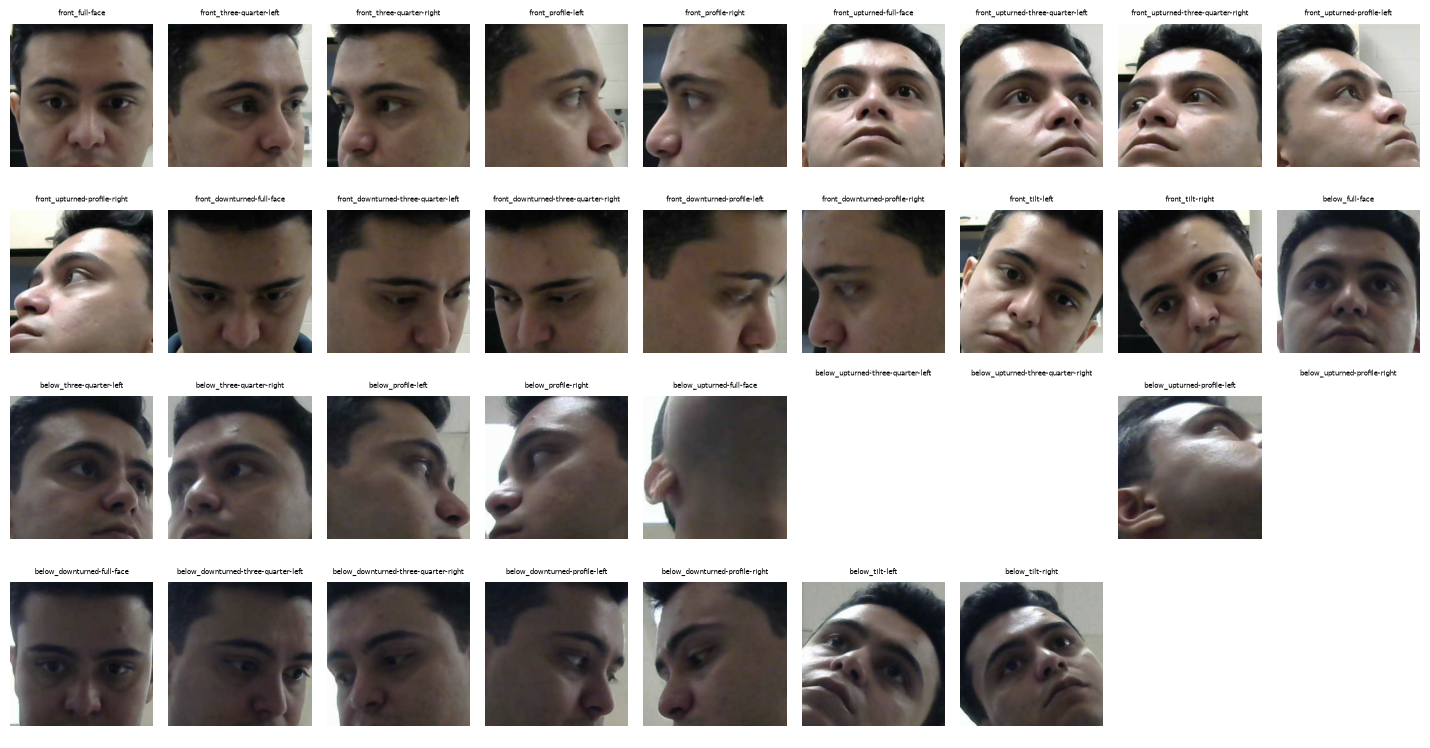

In [14]:
still = [r for r in manifest.itertuples() if clip_io.is_image(clip_io.clip_path(r))]
ncols = 9
fig, axes = plt.subplots(-(-len(still) // ncols), ncols, figsize=(1.6 * ncols, 1.9 * -(-len(still) // ncols)), squeeze=False)
for ax in axes.flat:
    ax.axis('off')
for ax, row in zip(axes.flat, still):
    _, _, img = next(clip_io.iter_frames(clip_io.clip_path(row)))
    face_conf, box = detect(img)
    if box is not None and face_conf >= DET_THRESHOLD:
        face = Image.fromarray(cv2.cvtColor(crop_face(img, box), cv2.COLOR_BGR2RGB))
        ax.imshow(transforms.CenterCrop(224)(transforms.Resize(256)(face)))
    ax.set_title(row.clip_id, fontsize=5)
plt.tight_layout()
plt.show()

### Standard plots per clip

Video clips only (time series need more than one frame).

In [15]:
for clip_id, df in out.groupby('clip_id'):
    if len(df) < 2:
        continue
    plots.plot_face_conf(df)
    plots.plot_pose(df)
    plt.show()

### Plausibility and stability (no ground truth)

- Value ranges: do the angles look reasonable for what happens in each clip?
- Jitter: median absolute frame-to-frame change on detected frames. A high value on a still face means a noisy model.

In [16]:
angle_cols = [c for c in schema.POSE_COLUMNS if c in out]
display(detected[angle_cols].describe().T.round(3))

# Jitter needs consecutive frames, so only video clips count
multi = detected.groupby('clip_id').filter(lambda d: len(d) > 1)
if len(multi):
    jitter = multi.groupby('clip_id')[angle_cols].apply(lambda d: d.diff().abs().median())
    display(jitter.rename(columns=lambda c: c.replace('_deg', '_jitter_deg')))
else:
    print('no multi-frame clips yet: jitter skipped')

,count,mean,std,min,25%,50%,75%,max
pose_yaw_deg,31.0,7.383,38.537,-69.819,-11.848,2.256,36.223,75.758
pose_pitch_deg,31.0,11.907,49.499,-48.179,-14.473,-2.630,16.385,171.582
pose_roll_deg,31.0,-9.961,46.568,-176.182,-17.344,0.027,12.743,48.935


no multi-frame clips yet: jitter skipped


### Failure cases

Frames where the face was missed or detected with low confidence. Look at a few to see why (pose, occlusion, lighting, blur).

In [17]:
failures = plots.failure_frames(out, threshold=DET_THRESHOLD)
display(failures.groupby('clip_id').size().rename('n_failures').to_frame())
failures.head(20)

,n_failures
clip_id,
below_upturned-profile-right,1
below_upturned-three-quarter-left,1
below_upturned-three-quarter-right,1


,clip_id,frame,timestamp_ms,face_conf
14,below_upturned-profile-right,0,0.0,0.0
15,below_upturned-three-quarter-left,0,0.0,0.0
16,below_upturned-three-quarter-right,0,0.0,0.0


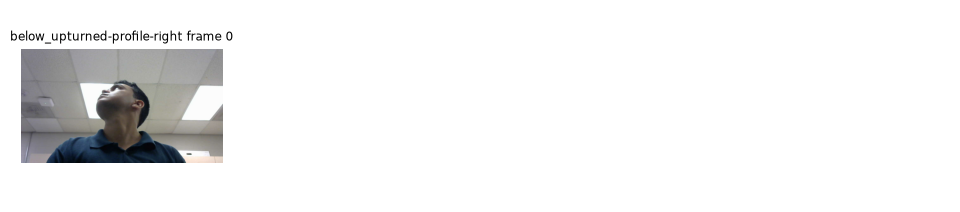

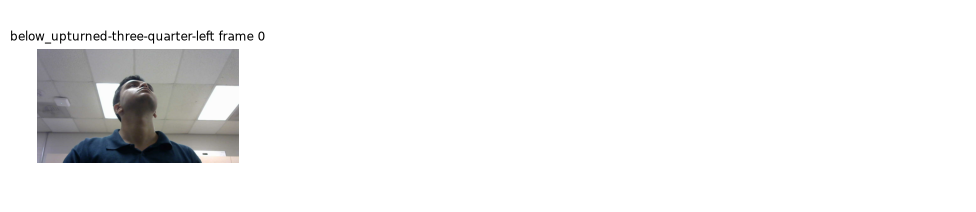

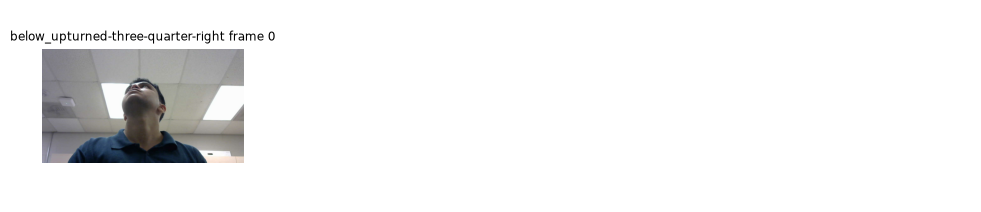

In [18]:
def show_frames(clip_id, frames, ncols=4):
    row = manifest.set_index('clip_id').loc[clip_id]
    wanted = set(frames)
    images = [(f, img) for f, _, img in clip_io.iter_frames(clip_io.clip_path(row), rgb=True) if f in wanted]
    if not images:
        return
    nrows = -(-len(images) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(3 * ncols, 2.5 * nrows), squeeze=False)
    for ax in axes.flat:
        ax.axis('off')
    for ax, (f, img) in zip(axes.flat, images):
        ax.imshow(img)
        ax.set_title(f'{clip_id} frame {f}', fontsize='small')
    plt.show()

# Up to 8 evenly spaced failure frames per clip
for clip_id, f in failures.groupby('clip_id'):
    show_frames(clip_id, f['frame'].iloc[np.linspace(0, len(f) - 1, min(8, len(f))).astype(int)])

### Comparison with 6DRepNet

Same pictures, same detector, different crop margin and model. Needs `outputs/6DRepNet/` from notebook 05. Differences are in degrees (6DRepNet360 − 6DRepNet).

In [19]:
OTHER = '6DRepNet'
other = clip_io.load_outputs(OTHER, manifest['clip_id'])
pose_cols = schema.POSE_COLUMNS
both = (
    out.set_index('clip_id')[['face_conf'] + pose_cols]
    .join(other.set_index('clip_id')[['face_conf'] + pose_cols], lsuffix=f'_{MODEL}', rsuffix=f'_{OTHER}')
)
for c in pose_cols:
    both[c.replace('_deg', '_diff_deg')] = both[f'{c}_{MODEL}'] - both[f'{c}_{OTHER}']
compare = manifest.set_index('clip_id')[['camera', 'head_yaw', 'head_pitch', 'head_roll', 'approx_head_yaw_deg']].join(both)
display(compare.round(1))
display(compare[[c.replace('_deg', '_diff_deg') for c in pose_cols]].abs().describe().round(1))

,camera,head_yaw,head_pitch,head_roll,approx_head_yaw_deg,face_conf_6DRepNet360,pose_yaw_deg_6DRepNet360,pose_pitch_deg_6DRepNet360,pose_roll_deg_6DRepNet360,face_conf_6DRepNet,pose_yaw_deg_6DRepNet,pose_pitch_deg_6DRepNet,pose_roll_deg_6DRepNet,pose_yaw_diff_deg,pose_pitch_diff_deg,pose_roll_diff_deg
clip_id,,,,,,,,,,,,,,,,
front_full-face,front,full-face,level,none,0.0,0.9,1.6,-14.3,-0.4,0.9,0.1,-8.8,1.3,1.5,-5.5,-1.8
front_three-quarter-left,front,three-quarter-left,level,none,45.0,0.9,42.7,-7.9,0.0,0.9,37.8,-4.3,0.9,4.9,-3.6,-0.9
front_three-quarter-right,front,three-quarter-right,level,none,-45.0,0.9,-43.0,-10.5,-4.9,0.9,-46.4,-6.4,-6.9,3.4,-4.1,2.0
front_profile-left,front,profile-left,level,none,90.0,0.9,75.1,52.8,-59.5,0.9,76.4,2.9,1.1,-1.3,50.0,-60.6
front_profile-right,front,profile-right,level,none,-90.0,0.9,-69.8,-2.6,0.5,0.9,-75.3,-8.4,-12.9,5.5,5.8,13.4
front_upturned-full-face,front,full-face,upturned,none,0.0,0.9,2.3,16.4,12.7,0.9,-1.4,32.4,-0.7,3.7,-16.0,13.4
front_upturned-three-quarter-left,front,three-quarter-left,upturned,none,45.0,0.9,21.8,13.1,4.1,0.9,18.8,31.0,-11.3,2.9,-17.9,15.4
front_upturned-three-quarter-right,front,three-quarter-right,upturned,none,-45.0,0.9,-34.6,29.3,14.0,0.9,-22.2,36.4,11.0,-12.4,-7.0,3.0
front_upturned-profile-left,front,profile-left,upturned,none,90.0,0.9,50.5,81.9,-68.4,0.9,41.2,42.7,-32.4,9.2,39.2,-36.0


,pose_yaw_diff_deg,pose_pitch_diff_deg,pose_roll_diff_deg
count,31.0,31.0,31.0
mean,12.4,26.6,15.6
std,22.1,51.3,26.4
min,0.2,1.4,0.3
25%,2.1,6.1,2.1
50%,3.8,9.5,4.5
75%,10.7,19.6,15.7
max,95.1,268.7,123.6
